# E103 · A few holdouts for many campaigns: calibrating propensity estimates with a hierarchical model of their bias

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify (the third brand-lift notebook, after E101 and E102) |
| **Data** | Real: the **Criteo Uplift Prediction Dataset v2.1** (Diemert et al. 2018; CC BY-NC-SA 4.0), E101's 300,000-user sample. As in E102, the **45,100 control users** are the audience: their observed visits are their no-ad visits, and we simulate only who sees an ad. Each simulated campaign takes its own 20,000 of them, its own targeting and reach, and a known true effect, so every estimate can be scored |
| **You will learn** | Why the error of a propensity estimate is **additive** in the true effect, so a placebo run measures it exactly · a **portfolio** of campaigns, all measured by propensity scores, a few with a **randomised holdout** · a **hierarchical model of the bias** across campaigns, $b_j \sim N(\mu_{\text{type}} + \beta\,\text{reach}, \tau)$, fitted jointly with the true effects; prior predictive checks · a **funnel** with a latent effect per campaign and its fix, integrating the effects out · **shrinkage** of per-campaign bias, posterior predictive bias for an untested campaign, **calibrated intervals** · **leave-one-holdout-out** refits with a compiled nutpie model · an **exact grid posterior** for thousands of portfolios, checked against PyMC · **decision value**: regret and wrong continue/cut decisions against the number of holdouts and against how predictable the bias is · which campaigns to test, and what **selection** of holdouts does to the calibration |

In [1]:
import os

for v_ in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[v_] = "1"  # nutpie runs chains as threads: a BLAS pool per chain would fight over the cores

import logging
import sys
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import nutpie
import pandas as pd
import pymc as pm
from scipy import special, stats

from pymc_challenges import data

RANDOM_SEED = 103
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="arviz")
warnings.filterwarnings("ignore", message=".*Potential.*")
sys.modules.pop("jax", None)  # arviz leaves a lazy jax stub that makes matplotlib import all of JAX
pd.set_option("display.width", 160)
T_START = time.time()

BLUE, ORANGE, AQUA, PURPLE, RED = "#2a78d6", "#eb6834", "#1baf7a", "#8c5ac8", "#c8384e"
INK, MUTED, LIGHT = "#222222", "#8a8984", "#d9d8d3"
TYPES = ["retargeting", "broad", "prospecting"]
TCOL = {"retargeting": RED, "broad": AQUA, "prospecting": BLUE}
print(f"PyMC {pm.__version__}, ArviZ {az.__version__}")

PyMC 6.3.2, ArviZ 1.3.0


## The setting

E101 found that a propensity analysis overstated one campaign's effect on the exposed by about 5
points of visits. E102 showed that the error can go either way - retargeting overstates,
suppression lists and prospecting understate - and that nothing in the observational data says
which. Both ended with the same advice: keep a randomised holdout.

A brand team runs dozens of campaigns a year, and a holdout on every one is expensive: it means
not advertising to part of the audience, waiting for the survey, and paying for it. The team asks
the obvious question. **If every campaign is measured with the propensity analysis and only a few
also get a holdout, can those few teach us how wrong the propensity numbers are for the rest - and
does that make our decisions better?**

On a campaign with a holdout we see two estimates of the same quantity, the propensity estimate
$\hat\theta^{\text{PS}}_j$ and the experimental one, and their difference is a noisy measurement
of the propensity estimate's **bias** for that campaign. A handful of such measurements is a small
data set about bias. A hierarchical model learns from it the typical bias, how it depends on
things we know about each campaign - its kind of targeting, its reach - and, crucially, **how much
it varies** around that prediction, a standard deviation we call $\tau$. Every campaign without a
holdout is then corrected by its predicted bias and its interval widened by $\tau$. This is
partial pooling in the sense of Rubin's (1981) eight schools, turned from the effects to the
errors of an estimator. Gordon, Zettelmeyer, Bhargava & Chapsky (2019) supply the warning: across
15 Facebook campaigns run as experiments, the bias of observational methods varied widely, so
$\tau$ may be large. Gordon, Moakler & Zettelmeyer (2023, arXiv 2304.06828, revised 2026) supply
the encouragement: their "predicted incrementality by experimentation" treats 2,226 experimental
outcomes from 998 Meta experiments as observations and predicts the experimental result from
campaign-level metrics available without a control group, with an out-of-sample $R^2$ of 0.88 for
incremental conversions per dollar. Carrying a correction from tested to untested campaigns is
also a question of transportability (Pearl & Bareinboim 2014): it is only as good as the
similarity between them.

We test the idea where the answer is known. Each simulated campaign is built on E102's real users
with its own audience, targeting type, reach and true effect; the analyst runs E101's propensity
analysis on every campaign, and a ghost-ad holdout survey of 3,000 respondents, drawn from real
rows, on a few. We then compare decisions made from raw propensity estimates, from the experiments
alone, and from calibrated estimates, on the same simulated portfolios.

| part | question | tool |
|---|---|---|
| A | What does a portfolio of campaigns look like? | E102's placebo machinery; 720 campaigns in four worlds of more or less predictable bias; additivity of the bias; ghost-ad experiments from real rows |
| B | What can the holdouts teach? | a hierarchical model of the bias in PyMC; prior predictive; a funnel and the marginal model; shrinkage |
| C | How good are the calibrated estimates? | calibrated against raw intervals; leave-one-holdout-out refits |
| D | Do they improve decisions? | an exact grid posterior checked against PyMC; regret and wrong decisions over 120 portfolios against the number of holdouts and the spread of the bias |
| E | Which campaigns should get the holdouts? | random, designed, and four kinds of selection |
| F | What should the brand team do? | the decision |

## A · A portfolio of campaigns on real users

In [2]:
data.describe("e101_criteo_uplift")
raw = np.load(data.path("e101_criteo_uplift"))
X = raw["X"].astype(float)
T = raw["treatment"].astype(int)
D_real = raw["exposure"].astype(int)
VISIT = raw["visit"].astype(float)
N = len(T)
ctl, tst = T == 0, T == 1
REACH_REAL = D_real[tst].mean()


def normal_scores(A):
    """Rank-based normal scores per column (ties share a rank)."""
    return np.column_stack([stats.norm.ppf((stats.rankdata(a) - 0.5) / len(a)) for a in A.T])


def fit_map(Z, y, prior_sd=0.5, a0=0.0, a_sd=1.5, iters=60):
    """Posterior mode of a logistic regression with N(a0, a_sd) intercept and N(0, prior_sd) slopes (Newton)."""
    Z1 = np.column_stack([np.ones(len(Z)), Z])
    prec = np.r_[1 / a_sd ** 2, np.full(Z.shape[1], 1 / prior_sd ** 2)]
    mu0 = np.r_[a0, np.zeros(Z.shape[1])]
    b = mu0.copy()
    for _ in range(iters):
        p = special.expit(Z1 @ b)
        g = Z1.T @ (y - p) - prec * (b - mu0)
        H = (Z1 * (p * (1 - p))[:, None]).T @ Z1 + np.diag(prec)
        step = np.linalg.solve(H, g)
        step *= min(1.0, 2.0 / max(np.abs(step).max(), 1e-12))    # damped: never move a log-odds by more than 2
        b += step
        if np.abs(step).max() < 1e-8:
            break
    return b


# E102's construction: the analyst sees 11 features; u is what f8 knows about visiting beyond them
R = normal_scores(X)
Zall = np.column_stack([R, R ** 2])
Zall = (Zall - Zall.mean(0)) / Zall.std(0)
HIDDEN = 8
SEEN = [k for k in range(12) if k != HIDDEN]
Zseen = Zall[:, SEEN + [12 + k for k in SEEN]]
tu = tst & (D_real == 0)
a0_v = special.logit(VISIT[tu].mean())
shift = (np.column_stack([np.ones(N), Zall]) @ fit_map(Zall[tu], VISIT[tu], a0=a0_v)
         - np.column_stack([np.ones(N), Zseen]) @ fit_map(Zseen[tu], VISIT[tu], a0=a0_v))
Zp = Zseen[ctl]
Z1p = np.column_stack([np.ones(len(Zp)), Zp])
Y0 = VISIT[ctl]                                                     # the audience's no-ad visits
n = len(Y0)
resid = shift[ctl] - Z1p @ np.linalg.lstsq(Z1p, shift[ctl], rcond=None)[0]
u = stats.norm.ppf((stats.rankdata(resid) - 0.5) / n)               # hidden engagement, N(0, 1)
eta = Z1p @ fit_map(Zseen[tst], D_real[tst], a0=special.logit(REACH_REAL))
eta = (eta - eta.mean()) / 1.7                                      # the real campaign's visible targeting
print(f"audience: {n:,} control users, visit rate {Y0.mean():.4f}; hidden trait u: corr with visits "
      f"{np.corrcoef(u, Y0)[0, 1]:.3f}")

e101_criteo_uplift: npz. A simple random sample of 300,000 of the 13,979,592 users in Criteo's pooled incrementality tests (randomised holdouts; several advertisers' tests sub-sampled to one treatment ratio): X (300000, 12) float32 anonymised features f0-f11 (float64 in the source), treatment (1 = test arm, randomised, ~85%), exposure (1 = the user was actually shown an ad; only possible in test), visit (visited the advertiser's site), conversion, row (row in the source). Plus EXACT full-data counts for the cells control / test-unexposed / test-exposed: cell_n, cell_visit, cell_conversion (3,), and per-cell feature sums cell_xsum, cell_xsq (3, 12); full-data sufficient statistics of a 91-column basis of the features' normal scores (1, r, r^2, pairwise products): basis_zz (arm, 91, 91), basis_zy (arm, outcome, 91), basis_cell_sum (3, 91); n_total, seed. Absolute rates are not the campaign's: Criteo down-sampled negatives non-uniformly.
  source: Criteo Uplift Prediction Dataset v2.1: Di

audience: 45,100 control users, visit rate 0.0373; hidden trait u: corr with visits 0.122


The cell rebuilds E102's ingredients exactly: the 45,100 control users, the analyst's 22
normal-score terms from eleven features, the hidden engagement trait $u$ (what feature f8 knows
about visiting beyond the other eleven, correlated 0.12 with visits, its effect concentrated in
its top tail), and the real campaign's targeting $\eta(x)$.

### A1 · Three kinds of campaign

A campaign $j$ takes a random 20,000 of the audience and delivers ads by E102's threshold rule,

$$D_i = \mathbf{1}\{\,s_j\,\eta(x_i) + \gamma_j u_i + \varepsilon_i > c_j\,\}, \qquad \varepsilon_i \sim N(0, 1),$$

with the bar $c_j$ set by the campaign's reach $r_j$ and $s_j \sim U(0.5, 1.5)$ for how hard it
targets the visible features. The brand team knows two things about each campaign: its **type**
and its **reach**. It does not know $\gamma_j$, how much delivery leaned on hidden engagement. The
types follow E102's mechanisms. **Retargeting** campaigns (reach 4-30%) lean toward engaged users,
$\gamma_j$ centred on $+0.7$, which E102 showed overstates the effect. **Prospecting** campaigns
(reach 15-70%) lean away from them, $\gamma_j$ centred on $-0.7$, which understates it. **Broad**
campaigns (reach 10-60%) ignore engagement ($\gamma_j$ centred on 0) but carry a suppression list
that keeps the 5-20% most engaged users out, which also understates it.

How tightly a type pins down its campaigns' delivery is the dial of this notebook. We build four
worlds. In **tight**, **moderate** and **loose**, $\gamma_j$ scatters around its type's centre
with standard deviation 0.1, 0.4 and 0.8. In **unpredictable**, the type label says nothing:
$\gamma_j \sim N(0, 0.7)$ for every campaign and there are no suppression lists, so retargeting,
broad and prospecting differ only in their reach and their true effects.

For each campaign the analyst runs E102's propensity analysis on its 20,000 users: posterior-mode
logistic models for exposure and for visits among the unexposed, and the AIPW estimate of the
effect on the exposed, with its influence-function standard deviation. We run it on the
**placebo**: the true effect is zero, so the estimate is the propensity analysis's bias for that
campaign,

$$\text{bias}_j = \hat\theta^{\,\text{PS}}_j - \theta_j .$$

Sixty campaigns per type and world, 720 in all, form a bank from which portfolios are drawn below.

In [3]:
E_CAP = 0.99
AUD = 20_000
REACH_RANGE = {"retargeting": (0.04, 0.30), "broad": (0.10, 0.60), "prospecting": (0.15, 0.70)}
GAMMA_MEAN = {"retargeting": 0.7, "broad": 0.0, "prospecting": -0.7}
SCENARIOS = {"tight": 0.1, "moderate": 0.4, "loose": 0.8, "unpredictable": None}


def aipw(d, idx, y=None):
    """The analyst's AIPW effect on the exposed (points) and its influence-function sd, on audience rows idx."""
    Z, Z1 = Zp[idx], Z1p[idx]
    y = Y0[idx] if y is None else y
    d = d.astype(float)
    t, un = d == 1, d == 0
    e = np.minimum(special.expit(Z1 @ fit_map(Z, d, a0=special.logit(d.mean()))), E_CAP)
    w = e / (1 - e)
    m0 = special.expit(Z1 @ fit_map(Z[un], y[un], a0=special.logit(max(y[un].mean(), 1e-4))))
    mu_w = np.average(y[un] - m0[un], weights=w[un])
    att = np.mean(y[t] - m0[t]) - mu_w
    phi = (t * (y - m0 - (att + mu_w)) - un * w * (y - m0 - mu_w) * t.sum() / w[un].sum()) / t.mean()
    return 100 * att, 100 * phi.std() / np.sqrt(len(y))


def deliver(kind, scen, rng_):
    """One campaign: its audience, delivery rule and exposures (who would be shown the ad)."""
    idx = np.sort(rng_.choice(n, AUD, replace=False))
    reach = rng_.uniform(*REACH_RANGE[kind])
    scale = rng_.uniform(0.5, 1.5)                                   # how hard it targets the visible features
    if SCENARIOS[scen] is None:
        gamma, supp = rng_.normal(0.0, 0.7), 0.0
    else:
        gamma = GAMMA_MEAN[kind] + rng_.normal(0.0, SCENARIOS[scen])
        supp = rng_.uniform(0.05, 0.2) if kind == "broad" else 0.0
    L = scale * eta[idx] + gamma * u[idx] + rng_.normal(size=AUD)
    if supp > 0:
        L[u[idx] > np.quantile(u[idx], 1 - supp)] = -np.inf          # suppression list: most engaged never exposed
    d = L > np.quantile(L, 1 - reach)
    return idx, d, {"type": kind, "scenario": scen, "reach": reach, "gamma": gamma, "suppressed": supp}


def make_campaign(kind, scen, rng_):
    idx, d, info = deliver(kind, scen, rng_)
    bias, ps_sd = aipw(d, idx)                                       # placebo: true effect 0, so this IS the bias
    return {**info, "bias": bias, "ps_sd": ps_sd, "base": 100 * Y0[idx][d].mean(), "exposed": int(d.sum()),
            "rows": idx[d].astype(np.int32)}


t0 = time.time()
rb = np.random.default_rng(RANDOM_SEED + 1)
bank = [make_campaign(k, sc, rb) for sc in SCENARIOS for k in TYPES for _ in range(60)]
ROWS = [c.pop("rows") for c in bank]                                 # each campaign's would-be-exposed users
bank = pd.DataFrame(bank)
print(f"{len(bank)} campaigns delivered and analysed in {time.time() - t0:.0f} s")
tab = bank.groupby(["scenario", "type"], sort=False).agg(
    bias=("bias", "mean"), bias_sd=("bias", "std"), ps_sd=("ps_sd", "mean"), base=("base", "mean"),
    reach=("reach", "mean"), exposed=("exposed", "mean"))
print(tab.round(2).to_string())
within = bank.groupby(["scenario", "type"], sort=False).bias.std().groupby("scenario", sort=False).mean()
print("bias sd within type, averaged over types: " + ", ".join(f"{s} {v:.1f}" for s, v in within.items()))

720 campaigns delivered and analysed in 24 s
                           bias  bias_sd  ps_sd   base  reach  exposed
scenario      type                                                    
tight         retargeting  5.42     1.53   0.97  11.89   0.17  3472.67
              broad       -3.51     1.12   0.68   4.87   0.35  6908.25
              prospecting -3.13     0.95   0.92   5.00   0.45  9006.08
moderate      retargeting  4.87     2.37   0.94  11.49   0.18  3568.48
              broad       -3.30     1.11   0.62   4.53   0.35  7087.25
              prospecting -3.06     1.33   0.82   4.69   0.47  9305.53
loose         retargeting  4.15     4.08   0.82  11.07   0.18  3524.47
              broad       -3.39     1.47   0.67   4.75   0.34  6832.95
              prospecting -2.16     2.40   0.77   5.17   0.40  8077.70
unpredictable retargeting  1.25     4.03   1.07   9.94   0.18  3502.80
              broad       -0.00     3.35   0.86   6.73   0.36  7138.75
              prospecting  0.07 

The 720 propensity analyses take about 25 seconds. In the three worlds where type means something,
the bias follows the type as E102 predicts: retargeting overstates the effect by 4.2-5.4 points on
average and the other two types understate it by 2.2-3.5. The spread within a type grows with the
dial, from about 1 to 1.5 points in the tight world to 4 for retargeting in the loose one; part of
it, even in the tight world, comes from reach and from the noise of a propensity analysis on
20,000 users (its own standard deviation is 0.6-1.1 points). Averaged over types, the within-type
spread is **1.2, 1.6, 2.6 and 3.5 points** in the four worlds. In the unpredictable world the type
means are within about a point of zero (retargeting +1.3) and each type spreads by 3.2-4.0 points:
the bias is as large as anywhere else, but nothing the team knows predicts its sign.

### A2 · The bias does not depend on the effect

Using placebo runs to measure the bias of campaigns that do have an effect rests on one property
of these estimators. The outcome model is fitted on the unexposed users, and the weights come from
the exposure model; neither sees the exposed users' outcomes. A real effect changes only those
outcomes, so it raises the exposed mean by exactly the realised effect and leaves everything else
unchanged:

$$\hat\theta^{\,\text{PS}}_j(\text{with effect}) = \theta_j + \hat\theta^{\,\text{PS}}_j(\text{placebo}).$$

One check on a retargeting campaign in which the ad turns 5% of the exposed non-visitors into
visitors:

In [4]:
rc = np.random.default_rng(RANDOM_SEED + 2)
idx_, d_, info_ = deliver("retargeting", "moderate", rc)
lift = rc.random(AUD) < 0.05                                         # who the ad turns into a visitor
y_ad = np.where(d_ & lift, 1.0, Y0[idx_])
att_true = 100 * (y_ad[d_] - Y0[idx_][d_]).mean()
est_ad, _ = aipw(d_, idx_, y_ad)
est_0, _ = aipw(d_, idx_)
print(f"true effect {att_true:.4f}; estimate with the effect {est_ad:.4f}; placebo estimate {est_0:.4f}; "
      f"estimate - truth - placebo = {est_ad - att_true - est_0:.1e}")

true effect 4.3527; estimate with the effect 5.7724; placebo estimate 1.4197; estimate - truth - placebo = -4.4e-16


The difference is zero to machine precision: the estimate is the true 4.35 points plus the
placebo's 1.42. So a campaign's propensity estimate is its true effect plus its bank bias, and we
can give each campaign a fresh true effect without rerunning its analysis.

### A3 · Effects, costs and holdouts

A **portfolio** is 40 campaigns drawn from one world's bank. Each gets a true effect on the
exposed, $\theta_j$, in points of visits, from a gamma distribution whose mean depends on the type
(2, 3 and 3.5 points for retargeting, broad and prospecting: retargeting reaches people who would
come anyway) and falls with reach (diminishing returns), and a **break-even effect**
$c_j \sim U(1, 6)$ points: the effect at which the campaign's next flight pays for itself. The
decision is to continue a campaign or cut it, and continuing earns $\theta_j - c_j$ (visits per
100 exposed users, valued at the break-even rate). About a third (34%) of the campaigns are worth
continuing.

A tested campaign gets a **ghost-ad holdout survey**, the design E101 recommended: 1,500 exposed
respondents and 1,500 randomly held-out respondents who would have been exposed, drawn with
replacement from the campaign's would-be-exposed users. The held-out respondents' outcomes are
their real no-ad visits; the exposed respondents get the ad's effect on top of theirs. The
estimate is the difference of the two means, unbiased for $\theta_j$, with standard error

$$\text{se}_j = \sqrt{\hat p_{1}(1-\hat p_{1})/1500 + \hat p_{0}(1-\hat p_{0})/1500}.$$

Here is one portfolio from the moderate world, with 12 campaigns tested, four of each type, spread
across reach.

In [5]:
J, NS = 40, 1500                                                     # campaigns per portfolio, respondents per arm
LIFT_MEAN = {"retargeting": 2.0, "broad": 3.0, "prospecting": 3.5}


def experiment(j_bank, theta, rng_):
    """A ghost-ad holdout survey from real rows: NS exposed and NS held-out would-be-exposed respondents."""
    rows = ROWS[j_bank]
    y_c = Y0[rng_.choice(rows, NS)]                                  # held out: their real no-ad visits
    y_t = Y0[rng_.choice(rows, NS)]
    p = theta / (100 - bank.base[j_bank])                            # the ad converts this share of non-visitors
    y_t = np.where(y_t == 1, 1.0, (rng_.random(NS) < p).astype(float))
    return 100 * (y_t.mean() - y_c.mean()), 100 * np.sqrt(y_t.var() / NS + y_c.var() / NS)


def new_portfolio(scen, rng_):
    """40 campaigns from the scenario's bank, fresh true effects, costs and experiments."""
    pick = rng_.choice(np.flatnonzero(bank.scenario == scen), J, replace=False)
    port = bank.loc[pick, ["type", "reach", "gamma", "suppressed", "bias", "ps_sd", "base"]].reset_index(drop=True)
    port["bank"] = pick
    mean = port.type.map(LIFT_MEAN).to_numpy() * (1.3 - 0.9 * port.reach.to_numpy())
    port["theta"] = rng_.gamma(2.25, mean / 2.25)                    # true effect on the exposed (points)
    port["cost"] = rng_.uniform(1.0, 6.0, J)                         # break-even effect (points)
    port["est"] = port.theta + port.bias                             # the propensity estimate
    ex = [experiment(j, th, rng_) for j, th in zip(pick, port.theta)]
    port["exp"], port["se"] = [e[0] for e in ex], [e[1] for e in ex]
    return port


def test_order(port, rule, rng_, susp_sd=1.0):
    """Order in which campaigns get a holdout; the first k are tested."""
    ty, rz = port.type.to_numpy(), port.reach.to_numpy()
    if rule == "random":
        return rng_.permutation(J)
    if rule in ("designed", "suspicious within type"):
        if rule == "designed":                                      # spread over reach within each type
            vdc = lambda i: (sum(((i >> b) & 1) / 2 ** (b + 1) for b in range(8)) + 0.5) % 1
            lists = []
            for t in TYPES:
                g = np.flatnonzero(ty == t)
                g = g[np.argsort(rz[g])]
                o = [g[min(int(vdc(i) * len(g)), len(g) - 1)] for i in range(len(g))]
                o = list(dict.fromkeys(o))
                lists.append(o + [x for x in g if x not in o])
        else:                                                       # the team's hunch: bias plus noise
            sig = port.bias.to_numpy() + rng_.normal(0, susp_sd, J)
            lists = [list(np.flatnonzero(ty == t)[np.argsort(-sig[ty == t])]) for t in TYPES]
        s0 = rng_.integers(3)
        lists = lists[s0:] + lists[:s0]
        out = []
        while any(lists):
            for li in lists:
                if li:
                    out.append(li.pop(0))
        return np.array(out)
    if rule == "top estimates":
        return np.argsort(-port.est.to_numpy())
    if rule == "suspicious":
        return np.argsort(-(port.bias.to_numpy() + rng_.normal(0, susp_sd, J)))
    if rule == "retargeting only":
        g = rng_.permutation(np.flatnonzero(ty == "retargeting"))
        return np.r_[g, rng_.permutation(np.setdiff1d(np.arange(J), g))]


rp = np.random.default_rng(RANDOM_SEED + 3)
port = new_portfolio("moderate", rp)
K_MAIN = 12
tested = np.zeros(J, bool)
tested[test_order(port, "designed", rp)[:K_MAIN]] = True
port["tested"] = tested
show = port.copy()
show["raw bias"] = np.where(tested, show.est - show.exp, np.nan)
print(f"one portfolio: {J} campaigns, {tested.sum()} with a holdout; experiment sd {port.se[tested].min():.2f}-"
      f"{port.se[tested].max():.2f} points")
print(show[tested].sort_values("type")[["type", "reach", "theta", "est", "exp", "se", "raw bias", "bias"]]
      .round(2).to_string(index=False))
print(port.groupby("type")[["theta", "est", "bias"]].mean().round(2).to_string())

one portfolio: 40 campaigns, 12 with a holdout; experiment sd 0.81-1.41 points
       type  reach  theta   est   exp   se  raw bias  bias
      broad   0.23   3.03 -2.91  1.53 1.03     -4.44 -5.94
      broad   0.29   1.05 -2.76 -0.27 0.83     -2.50 -3.81
      broad   0.43   0.95 -3.12  0.47 0.83     -3.59 -4.07
      broad   0.19   8.26  4.41  6.73 1.13     -2.32 -3.85
prospecting   0.42   1.71 -0.81  3.07 0.83     -3.88 -2.53
prospecting   0.57   2.02 -1.59  1.67 0.82     -3.26 -3.62
prospecting   0.29   0.63 -3.13  1.20 0.81     -4.33 -3.76
prospecting   0.16   5.55  2.86  3.13 0.96     -0.27 -2.69
retargeting   0.12   0.67  1.17  1.13 1.18      0.04  0.51
retargeting   0.24   2.31  3.19  3.87 1.09     -0.68  0.88
retargeting   0.20   0.86  2.31  2.53 1.14     -0.22  1.44
retargeting   0.04   3.31  8.89  3.20 1.41      5.69  5.58
             theta   est  bias
type                          
broad         3.60 -0.07 -3.67
prospecting   2.38 -0.96 -3.34
retargeting   1.80  6.63  4.83

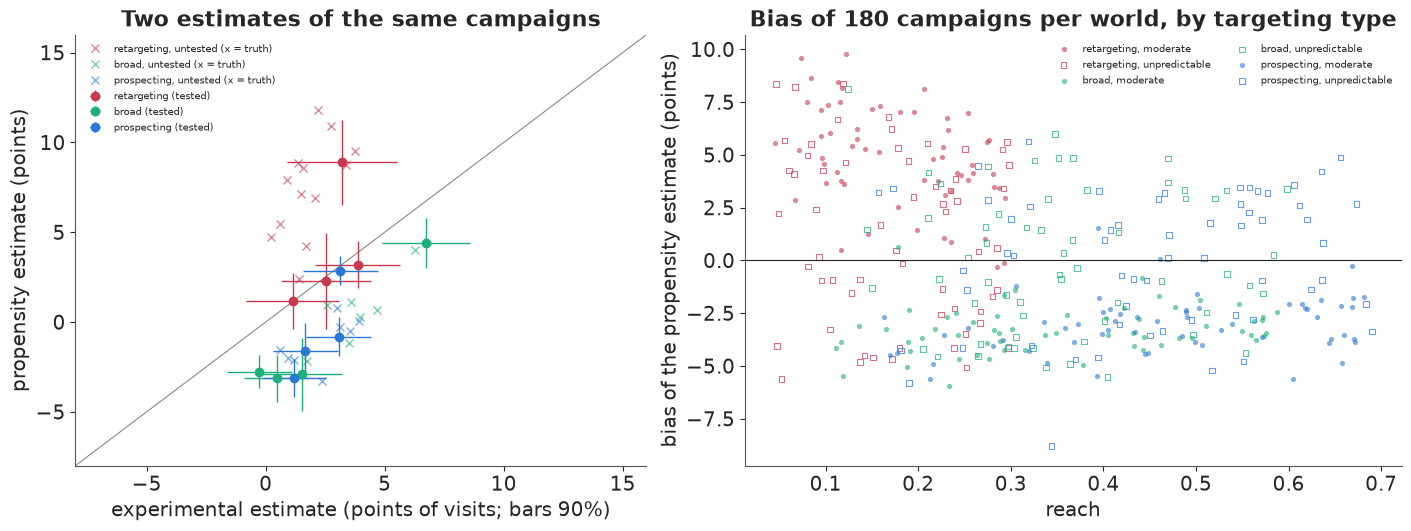

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1, 1.15]})
ax = axes[0]
lim = (-8, 16)
ax.plot(lim, lim, color=MUTED, lw=0.8)
for t in TYPES:
    s_ = port[(port.type == t) & port.tested]
    ax.errorbar(s_.exp, s_.est, xerr=1.645 * s_.se, yerr=1.645 * s_.ps_sd, fmt="o", color=TCOL[t], ms=6,
                capsize=0, lw=1, label=f"{t} (tested)")
    s_ = port[(port.type == t) & ~port.tested]
    ax.plot(s_.theta, s_.est, "x", color=TCOL[t], ms=6, alpha=0.6, label=f"{t}, untested (x = truth)")
ax.set(xlim=lim, ylim=lim, xlabel="experimental estimate (points of visits; bars 90%)",
       ylabel="propensity estimate (points)", title="Two estimates of the same campaigns")
ax.legend(fontsize=7.5, loc="upper left")
ax = axes[1]
for i, t in enumerate(TYPES):
    for sc, mk, dx in [("moderate", "o", -0.12), ("unpredictable", "s", 0.12)]:
        v = bank[(bank.type == t) & (bank.scenario == sc)]
        if sc == "moderate":
            ax.scatter(v.reach, v.bias, s=14, color=TCOL[t], marker=mk, alpha=0.6, lw=0, label=f"{t}, {sc}")
        else:                                                       # hollow squares, so both worlds stay visible
            ax.scatter(v.reach, v.bias, s=16, facecolors="none", edgecolors=TCOL[t], marker=mk, alpha=0.7,
                       lw=0.8, label=f"{t}, {sc}")
ax.axhline(0, color=INK, lw=0.8)
ax.set(xlabel="reach", ylabel="bias of the propensity estimate (points)",
       title="Bias of 180 campaigns per world, by targeting type")
ax.legend(fontsize=7.5, ncol=2, loc="upper right");

The experiments' standard errors are 0.8-1.4 points, a realistic size for a ghost-ad survey of
3,000. On the twelve tested campaigns the difference between the two estimates - the **raw bias**
- is negative for all eight broad and prospecting campaigns (-0.3 to -4.4 points), and for
retargeting it is near zero for three campaigns and +5.7 for the fourth, the 4%-reach campaign.
The true biases, which only we can see, tell the same story with less noise. Over all 40
campaigns, the retargeting ones report an average propensity estimate of 6.6 points against a true
1.8, while broad and prospecting report about -0.1 and -1.0 against true effects of 3.6 and 2.4:
taken at face value, the propensity numbers would keep most retargeting campaigns and cut most of
the others: they would keep the type with the smallest true effects and cut the types with the
largest.

In the left panel retargeting sits above the diagonal and the rest below it. In the right panel,
the bank, the type separates the sign of the bias almost perfectly in the moderate world (filled
dots) and not at all in the unpredictable one (hollow squares).

## B · A hierarchical model of the bias

Write $y_j = \hat\theta^{\text{PS}}_j$ for the propensity estimate of campaign $j$ and $e_j$ for
the experimental estimate where there is one. The model has two layers, one for the effects and
one for the bias:

$$\theta_j \sim N\big(\alpha_{\text{type}[j]} + \alpha_r\, z_j,\; s\big), \qquad
y_j \sim N\big(\theta_j + \beta_{\text{type}[j]} + \beta_r\, z_j,\; \tau\big), \qquad
e_j \sim N(\theta_j, \text{se}_j) \text{ if tested},$$

where $z_j = (r_j - 0.35)/0.2$ is the standardised reach. The second line is the hierarchical
model of bias, $b_j = y_j - \theta_j \sim N(\beta_{\text{type}} + \beta_r z_j, \tau)$: a predicted
bias from what the team knows, plus a campaign-specific part with spread $\tau$, which also
absorbs the propensity analysis's own sampling noise. The first line lets true effects differ by
type and reach too. That matters: a difference between the propensity estimates of retargeting and
prospecting campaigns could be a difference in effect or in bias, and only the experiments can say
which. A model that let the effect vary by type but the bias not would read every difference in
bias as a difference in effect.

The priors are in points of visits: mean effects by type $N(3, 3)$, a reach slope $N(0, 1.5)$,
$s \sim$ HalfNormal(3); mean biases by type $N(0, 4)$, a reach slope $N(0, 2)$, so a type's bias
could be as large as the 5-9 points of E101 and E102 in either direction; and $\tau \sim$
HalfNormal(4), from predictable bias to bias as wild as Gordon et al. found. The model works on
the campaigns' summary numbers only, as a brand team would.

### B1 · The model as written, and a funnel

The direct translation puts one latent $\theta_j$ per campaign (non-centred,
$\theta_j = m_j + s\,\xi_j$ with $\xi_j \sim N(0, 1)$) and both observations on top.

In [7]:
def model_arrays(port):
    t_idx = pd.Index(TYPES).get_indexer(port.type)
    rz = ((port.reach - 0.35) / 0.2).to_numpy()
    return t_idx, rz


def latent_model(port, mask):
    """The model as written: every campaign's true effect is a latent variable."""
    t_idx, rz = model_arrays(port)
    with pm.Model(coords={"campaign": np.arange(J), "type": TYPES}) as m:
        a_type = pm.Normal("a_type", 3.0, 3.0, dims="type")         # mean true effect by type
        a_reach = pm.Normal("a_reach", 0.0, 1.5)
        s = pm.HalfNormal("s", 3.0)                                  # spread of true effects
        z = pm.Normal("z", 0.0, 1.0, dims="campaign")
        theta = pm.Deterministic("theta", a_type[t_idx] + a_reach * rz + s * z, dims="campaign")
        b_type = pm.Normal("b_type", 0.0, 4.0, dims="type")         # mean bias by type
        b_reach = pm.Normal("b_reach", 0.0, 2.0)
        tau = pm.HalfNormal("tau", 4.0)                              # spread of the bias around its prediction
        pm.Normal("est", theta + b_type[t_idx] + b_reach * rz, tau, observed=port.est.to_numpy(), dims="campaign")
        pm.Potential("experiments", (mask * pm.logp(pm.Normal.dist(theta, port.se.to_numpy()),
                                                    np.nan_to_num(port.exp.to_numpy()))).sum())
    return m


t0 = time.time()
with latent_model(port, port.tested.to_numpy().astype(float)):
    idata_lat = pm.sample(random_seed=RANDOM_SEED, progressbar=False, target_accept=0.9)
sm_ = az.summary(idata_lat, var_names=["s", "tau"], round_to=4)
print(f"latent model: {time.time() - t0:.0f} s, divergences {int(idata_lat.sample_stats['diverging'].sum())}; "
      + "; ".join(f"{v}: r_hat {sm_.loc[v, 'r_hat']:.2f}, bulk ESS {sm_.loc[v, 'ess_bulk']:.0f}" for v in ["s", "tau"]))
del idata_lat

latent model: 9 s, divergences 111; s: r_hat 1.01, bulk ESS 361; tau: r_hat 1.06, bulk ESS 49


**Failure: a funnel in $\tau$.** Dozens of divergent transitions, sometimes over a hundred (60-115
in our runs; nutpie is not bit-reproducible), and $\tau$ mixes badly, with r_hat around 1.04-1.06
and a bulk ESS under 100, even at a target acceptance of 0.9. The geometry is the eight-schools
funnel moved to a new place. For the 28 untested campaigns, the only thing tying $\theta_j$ down
is $y_j$, with spread $\tau$; when $\tau$ is small, each $\theta_j$ is pinned to a narrow ridge,
when it is large, it floats, and the sampler needs a different step size in each regime. The
effects are already non-centred; the trouble is in $\tau$, which the usual reparameterisation of a
hierarchy does not reach.

**The fix is to integrate the effects out**, which here is exact because everything is Gaussian.
Given the hyperparameters, campaign $j$'s two estimates are jointly normal. Writing $m_j$ for the
expected effect and $\mu_j$ for the predicted bias, the propensity estimate has

$$y_j \sim N\big(m_j + \mu_j,\; \sqrt{s^2 + \tau^2}\big),$$

and the experiment, given it, is

$$e_j \mid y_j \sim N\Big(m_j + \frac{s^2}{s^2+\tau^2}\,(y_j - m_j - \mu_j),\;
\sqrt{\tfrac{s^2\tau^2}{s^2+\tau^2} + \text{se}_j^2}\Big).$$

The factor $s^2/(s^2+\tau^2)$ is how much of a surprising propensity estimate the model attributes
to the effect rather than to the bias: close to 1 when the bias is predictable ($\tau \ll s$),
close to 0 when it is not. The model now has ten parameters and no per-campaign latents. The
experiment term is a `pm.Potential` weighted by a 0/1 mask held in `pm.Data`, so the same compiled
model can later drop one holdout at a time. The true effects come back afterwards from their exact
conditional, a precision-weighted average of three pieces of information,

$$\theta_j \mid \cdot \sim N\Big(V_j\big[\tfrac{m_j}{s^2} + \tfrac{y_j - \mu_j}{\tau^2} + \tfrac{e_j}{\text{se}_j^2}\big],\; V_j\Big),
\qquad V_j^{-1} = \tfrac{1}{s^2} + \tfrac{1}{\tau^2} + \tfrac{1}{\text{se}_j^2},$$

the last term only for tested campaigns, drawn once for each posterior draw of the
hyperparameters. This is the calibrated estimate: the propensity estimate corrected by the
predicted bias, weighted by $1/\tau^2$, and shrunk toward what campaigns of its type and reach
usually achieve.

Before fitting, the prior predictive.

In [8]:
def calibration_model(port, mask):
    """The same model with every campaign's true effect integrated out (two Gaussian factors per campaign)."""
    t_idx, rz = model_arrays(port)
    est, ex, se = port.est.to_numpy(), np.nan_to_num(port.exp.to_numpy()), port.se.to_numpy()
    with pm.Model(coords={"campaign": np.arange(J), "type": TYPES}) as m:
        mask_ = pm.Data("mask", mask.astype(float), dims="campaign")
        a_type = pm.Normal("a_type", 3.0, 3.0, dims="type")
        a_reach = pm.Normal("a_reach", 0.0, 1.5)
        s = pm.HalfNormal("s", 3.0)
        b_type = pm.Normal("b_type", 0.0, 4.0, dims="type")
        b_reach = pm.Normal("b_reach", 0.0, 2.0)
        tau = pm.HalfNormal("tau", 4.0)
        m_j = a_type[t_idx] + a_reach * rz                           # expected true effect
        mu_b = b_type[t_idx] + b_reach * rz                          # predicted bias
        v = s ** 2 + tau ** 2
        pm.Normal("est", m_j + mu_b, pm.math.sqrt(v), observed=est, dims="campaign")
        k_ = s ** 2 / v                                              # the experiment, given the propensity estimate
        pm.Potential("experiments", (mask_ * pm.logp(
            pm.Normal.dist(m_j + k_ * (est - m_j - mu_b), pm.math.sqrt(s ** 2 * tau ** 2 / v + se ** 2)), ex)).sum())
    return m


def theta_draws(fit, port, mask, rng_):
    """True effects drawn from their exact conditional given each posterior draw of the hyperparameters."""
    po = az.extract(fit, var_names=["a_type", "a_reach", "s", "b_type", "b_reach", "tau"])
    t_idx, rz = model_arrays(port)
    m_j = po["a_type"].values[t_idx] + po["a_reach"].values * rz[:, None]
    mu_b = po["b_type"].values[t_idx] + po["b_reach"].values * rz[:, None]
    s, tau = po["s"].values, po["tau"].values
    se2 = port.se.to_numpy() ** 2
    prec = 1 / s ** 2 + 1 / tau ** 2 + (mask / se2)[:, None]
    num = (m_j / s ** 2 + (port.est.to_numpy()[:, None] - mu_b) / tau ** 2
           + (mask * np.nan_to_num(port.exp.to_numpy()) / se2)[:, None])
    return num / prec + rng_.normal(size=prec.shape) / np.sqrt(prec), po


cal = calibration_model(port, port.tested.to_numpy())
with cal:
    prior = pm.sample_prior_predictive(1000, random_seed=RANDOM_SEED)
pr = prior.prior
b_new = (pr["b_type"].values[0, :, :, None] + pr["tau"].values[0, :, None, None] * rp.normal(size=(1000, 3, 1)))
th_prior = pr["a_type"].values[0] + pr["s"].values[0, :, None] * rp.normal(size=(1000, 3))
pp_est = prior.prior_predictive["est"].values.ravel()
print("prior predictive, propensity estimates (points): 5/50/95% "
      + " / ".join(f"{v:.1f}" for v in np.percentile(pp_est, [5, 50, 95])))
print("prior predictive, bias of a new campaign of one type: 5/50/95% "
      + " / ".join(f"{v:.1f}" for v in np.percentile(b_new, [5, 50, 95])))
print("prior, true effect of a campaign: 5/50/95% "
      + " / ".join(f"{v:.1f}" for v in np.percentile(th_prior, [5, 50, 95])))
print(f"observed propensity estimates in the portfolio: {port.est.min():.1f} to {port.est.max():.1f}")

prior predictive, propensity estimates (points): 5/50/95% -9.0 / 3.1 / 15.2
prior predictive, bias of a new campaign of one type: 5/50/95% -9.7 / -0.2 / 9.0
prior, true effect of a campaign: 5/50/95% -3.8 / 3.1 / 9.5
observed propensity estimates in the portfolio: -3.3 to 11.8


The priors produce propensity estimates between about -9 and +15 points (5th and 95th percentiles)
where the portfolio's run from -3.3 to 11.8, so they cover the data without being much wider. A
new campaign's bias is a priori anywhere from about -10 to +9 points, symmetric around zero: the
model is not told that propensity methods overstate (E102 showed that lesson borrowed from the
wrong campaign does harm). True effects run from about -4 to +10 points, which allows the
occasional campaign that hurts.

In [9]:
t0 = time.time()
with cal:
    idata = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
print(f"sampled in {time.time() - t0:.0f} s; tuning steps {idata.posterior.attrs.get('tuning_steps')}; "
      f"divergences {int(idata.sample_stats['diverging'].sum())}")
summ = az.summary(idata, var_names=["a_type", "a_reach", "s", "b_type", "b_reach", "tau"], round_to=4)
print(summ[["mean", "sd", "eti89_lb", "eti89_ub", "r_hat", "ess_bulk"]].round(2).to_string())
true_b = bank[bank.scenario == "moderate"].groupby("type").bias.mean().reindex(TYPES)
print("bank's mean bias by type (moderate world): " + ", ".join(f"{t} {v:+.2f}" for t, v in true_b.items()))

sampled in 8 s; tuning steps 400; divergences 0
                     mean    sd  eti89_lb  eti89_ub  r_hat  ess_bulk
a_type[retargeting]  4.34  1.33      2.21      6.43    1.0   1143.71
a_type[broad]        2.58  0.97      1.09      4.16    1.0   2092.69
a_type[prospecting]  2.18  0.85      0.86      3.54    1.0   3114.71
a_reach              0.07  0.79     -1.21      1.35    1.0   1387.57
s                    1.98  0.45      1.29      2.73    1.0   1451.45
b_type[retargeting]  1.93  1.35     -0.17      4.17    1.0   1106.20
b_type[broad]       -2.60  0.94     -4.00     -1.07    1.0   2010.23
b_type[prospecting] -2.95  0.82     -4.24     -1.64    1.0   3251.14
b_reach             -0.41  0.80     -1.66      0.91    1.0   1423.63
tau                  1.81  0.49      1.05      2.60    1.0   1521.74
bank's mean bias by type (moderate world): retargeting +4.87, broad -3.30, prospecting -3.06


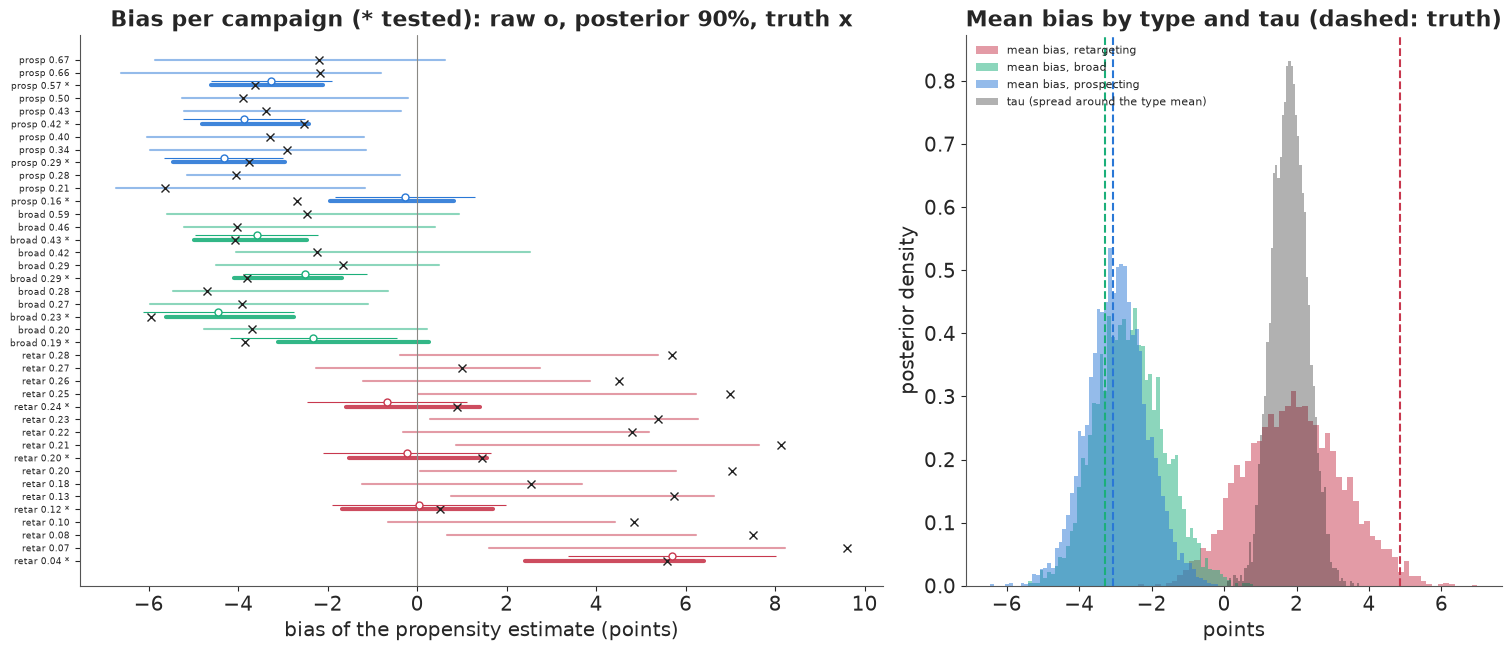

In [10]:
TH_post, post = theta_draws(idata, port, port.tested.to_numpy().astype(float), rp)   # (campaign, draws)
B_post = port.est.to_numpy()[:, None] - TH_post
fig, axes = plt.subplots(1, 2, figsize=(15, 6.4), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
order_ = np.lexsort((port.reach.to_numpy(), pd.Index(TYPES).get_indexer(port.type)))
for row, j in enumerate(order_):
    t, col = port.type[j], TCOL[port.type[j]]
    lo, hi = np.percentile(B_post[j], [5, 95])
    ax.plot([lo, hi], [row, row], color=col, lw=3 if port.tested[j] else 1.5, alpha=0.9 if port.tested[j] else 0.5)
    ax.plot(port.bias[j], row, "x", color=INK, ms=6)
    if port.tested[j]:
        rb_ = port.est[j] - port.exp[j]
        ax.errorbar(rb_, row + 0.35, xerr=1.645 * port.se[j], fmt="o", mfc="white", color=col, ms=5, capsize=0,
                    lw=0.8)
ax.axvline(0, color=MUTED, lw=0.8)
ax.set_yticks(np.arange(J), [f"{port.type[j][:5]} {port.reach[j]:.2f}{' *' if port.tested[j] else ''}"
                             for j in order_], fontsize=6.5)
ax.set(xlabel="bias of the propensity estimate (points)",
       title="Bias per campaign (* tested): raw o, posterior 90%, truth x")
ax = axes[1]
for i, t in enumerate(TYPES):
    v = post["b_type"].values[i]
    ax.hist(v, bins=60, density=True, color=TCOL[t], alpha=0.5, label=f"mean bias, {t}")
    ax.axvline(true_b[t], color=TCOL[t], lw=1.5, ls="--")
ax.hist(post["tau"].values, bins=60, density=True, color=INK, alpha=0.35, label="tau (spread around the type mean)")
ax.set(xlabel="points", ylabel="posterior density", title="Mean bias by type and tau (dashed: truth)")
ax.legend(fontsize=8);

The marginal model samples cleanly: no divergences, r_hat 1.00 and at least 1,100 effective draws
for every parameter, in a few seconds.

**What the twelve holdouts taught.** Broad and prospecting campaigns understate their effect by
about 2.6 and 3.0 points (89% intervals about -4.0 to -1.1 and -4.2 to -1.6), close to the bank's
true type means of -3.3 and -3.1. Retargeting is the weak spot. Its posterior mean bias is about
+1.9 points with an interval from -0.2 to +4.2, against a true type mean of +4.9, because three of
the four tested retargeting campaigns happened to have small biases (0.5-1.4 points); the fourth,
at 4% reach, had 5.6. The model knows it is unsure - retargeting's interval is the widest - but
its centre is off, a fact about this draw of holdouts that part D averages over. The reach slope
of the bias is not identified (-0.4, interval -1.7 to +0.9), and $\tau$ is about 1.8 points
(1.0-2.6).

In the shrinkage plot (left), each tested campaign (asterisk) shows its raw bias with the
experiment's 90% bar (open circle) and its posterior bias (thick bar), pulled toward its type's
mean. Untested campaigns get thin bars, essentially their type's predictive distribution of bias.
For broad and prospecting the bars sit on the true biases (crosses); for retargeting most true
biases lie in the upper part of the bars or beyond them, the visible cost of a type mean learned
too low.

## C · Calibrating the campaigns without a holdout

For the 28 untested campaigns we compare two 90% intervals for the true effect: the raw one a
propensity analysis reports, its estimate plus or minus 1.645 influence-function standard
deviations, and the calibrated one from the posterior draws of $\theta_j$. Since we know every
$\theta_j$, we can count how often each covers it, and how many continue/cut decisions each
posterior mean gets wrong.

In [11]:
un = ~port.tested.to_numpy()
th = port.theta.to_numpy()
lo_c, hi_c = np.percentile(TH_post, [5, 95], axis=1)
lo_r, hi_r = port.est - 1.645 * port.ps_sd, port.est + 1.645 * port.ps_sd
cover_cal = np.mean(((th >= lo_c) & (th <= hi_c))[un])
cover_raw = np.mean(((th >= lo_r) & (th <= hi_r))[un])
mean_cal = TH_post.mean(1)
print(f"untested campaigns ({un.sum()}): 90% intervals cover the truth - raw propensity {cover_raw:.0%}, "
      f"calibrated {cover_cal:.0%}")
print(f"  mean width: raw {np.mean((hi_r - lo_r)[un]):.1f} points, calibrated {np.mean((hi_c - lo_c)[un]):.1f}")
inside = (th >= lo_c) & (th <= hi_c)
print("  calibrated intervals covering the truth, by type: " + ", ".join(
    f"{t} {inside[un & (port.type == t).to_numpy()].sum()} of {(un & (port.type == t).to_numpy()).sum()}"
    for t in TYPES) + "; misses above the truth (overstated): "
      + f"{np.sum(un & ~inside & (lo_c > th))}, below: {np.sum(un & ~inside & (hi_c < th))}")
print(f"  RMSE against the truth: raw {np.sqrt(np.mean((port.est - th)[un] ** 2)):.2f}, "
      f"calibrated {np.sqrt(np.mean((mean_cal - th)[un] ** 2)):.2f}")
c_ = port.cost.to_numpy()
for lab, est_ in [("raw", port.est.to_numpy()), ("calibrated", mean_cal)]:
    print(f"  wrong continue/cut decisions on the untested: {lab} {np.sum(((est_ > c_) != (th > c_))[un])} of {un.sum()}")
nb_ = post["b_type"].values + post["tau"].values[None] * rp.normal(size=post["b_type"].shape)
print("posterior predictive bias of a NEW campaign at 35% reach, 90% interval: " + ", ".join(
    f"{t} {np.percentile(nb_[i], 5):+.1f} to {np.percentile(nb_[i], 95):+.1f}" for i, t in enumerate(TYPES)))

untested campaigns (28): 90% intervals cover the truth - raw propensity 4%, calibrated 71%
  mean width: raw 2.4 points, calibrated 5.5
  calibrated intervals covering the truth, by type: retargeting 5 of 13, broad 7 of 7, prospecting 8 of 8; misses above the truth (overstated): 8, below: 0
  RMSE against the truth: raw 4.88, calibrated 2.33
  wrong continue/cut decisions on the untested: raw 17 of 28
  wrong continue/cut decisions on the untested: calibrated 10 of 28
posterior predictive bias of a NEW campaign at 35% reach, 90% interval: retargeting -1.6 to +6.0, broad -5.9 to +0.9, prospecting -6.5 to +0.4


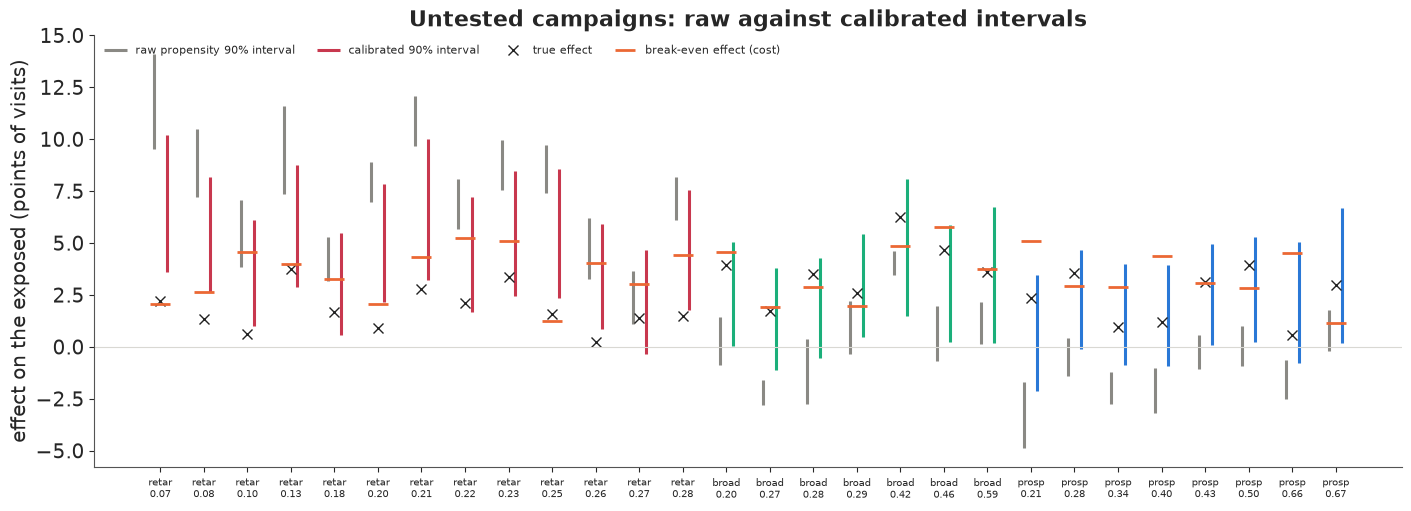

In [12]:
fig, ax = plt.subplots(figsize=(14, 5))
uj = [j for j in order_ if un[j]]
x = np.arange(len(uj))
ax.vlines(x - 0.15, lo_r[uj], hi_r[uj], color=MUTED, lw=2.2, label="raw propensity 90% interval")
ax.vlines(x + 0.15, lo_c[uj], hi_c[uj], color=[TCOL[port.type[j]] for j in uj], lw=2.2,
          label="calibrated 90% interval")
ax.plot(x, th[uj], "x", color=INK, ms=7, label="true effect")
ax.plot(x, c_[uj], "_", color=ORANGE, ms=14, mew=2, label="break-even effect (cost)")
ax.axhline(0, color=LIGHT, lw=0.8)
ax.set_xticks(x, [f"{port.type[j][:5]}\n{port.reach[j]:.2f}" for j in uj], fontsize=7)
ax.set(ylabel="effect on the exposed (points of visits)", title="Untested campaigns: raw against calibrated intervals")
ax.legend(fontsize=8, ncol=4, loc="upper left");

The raw propensity intervals are narrow, 2.4 points on average, and cover the truth for **one
campaign in 28** (4%). They are honest about sampling noise and blind to bias, the "tight and
wrong" of E101 in every campaign at once. The calibrated intervals are more than twice as wide,
5.5 points, and cover the truth for 20 of 28 (71%). The root-mean-square error of the point
estimate halves, from 4.9 to 2.3 points, and wrong continue/cut decisions among the untested fall
from 17 to about 10 or 11 (the count moves by one between runs).

Coverage is below 90% for the reason seen in the shrinkage plot. Every broad and prospecting
interval covers its truth, 15 of 15; retargeting manages 5 of 13, and all eight misses are on the
same side: the calibrated effect is still too high, because the bias learned from four retargeting
holdouts (about +2 points) is less than half the true type mean. The posterior predictive bias of
a *new* retargeting campaign, about -1.6 to +6.0 points, contains the true mean of +4.9, but the
13 untested retargeting campaigns share one error in the type mean. A calibration with four
holdouts per type can be off for a whole type at once.

### C1 · Leave one holdout out

A check a real team could run: drop one campaign's experiment, refit, and ask whether the
calibrated interval, built as if that campaign had no holdout, contains what its experiment reads.
The model is compiled once by nutpie and each refit swaps the mask with `with_data`. We also
record whether the interval covers the true effect.

In [13]:
compiled = nutpie.compile_pymc_model(cal)
loo_rows = []
t0 = time.time()
for j in np.flatnonzero(port.tested):
    mk = port.tested.to_numpy().astype(float)
    mk[j] = 0.0
    fit_ = nutpie.sample(compiled.with_data(mask=mk), chains=4, draws=1000, seed=RANDOM_SEED + int(j),
                         progress_bar=False)
    thj = theta_draws(fit_, port, mk, rp)[0][j]
    pred = thj + port.se[j] * rp.normal(size=thj.size)                # what its experiment would read
    loo_rows.append({"campaign": j, "type": port.type[j], "exp": port.exp[j], "truth": port.theta[j],
                     "lo": np.percentile(thj, 5), "hi": np.percentile(thj, 95),
                     "pit_exp": np.mean(pred < port.exp[j]),
                     "divergences": int(fit_.sample_stats["diverging"].sum())})
loo = pd.DataFrame(loo_rows)
loo["covers truth"] = (loo.truth >= loo.lo) & (loo.truth <= loo.hi)
print(f"{len(loo)} leave-one-holdout-out refits in {time.time() - t0:.0f} s; divergences {loo.divergences.sum()}")
print(loo.round(2).to_string(index=False))
print(f"held-out 90% intervals cover the true effect {loo['covers truth'].mean():.0%}; "
      f"experiment inside its predictive 90% {np.mean((loo.pit_exp > 0.05) & (loo.pit_exp < 0.95)):.0%}")

12 leave-one-holdout-out refits in 1 s; divergences 3
 campaign        type   exp  truth    lo   hi  pit_exp  divergences  covers truth
        0 prospecting  3.07   1.71 -0.54 4.48     0.74            0          True
        3 retargeting  1.13   0.67 -1.45 4.46     0.46            0          True
       12 retargeting  3.87   2.31 -0.61 4.82     0.83            0          True
       16       broad  1.53   3.03 -1.95 3.30     0.70            0          True
       22 prospecting  1.67   2.02 -0.78 5.39     0.38            0          True
       24 retargeting  2.53   0.86 -0.74 4.49     0.64            0          True
       27       broad -0.27   1.05 -1.09 4.15     0.15            0          True
       31 retargeting  3.20   3.31  3.78 9.60     0.06            0         False
       33 prospecting  1.20   0.63 -2.22 3.54     0.63            0          True
       34       broad  0.47   0.95 -1.41 4.09     0.32            0          True
       38 prospecting  3.13   5.55  1.34 7.5

Twelve refits take about a second, with a handful of divergences in total (0-4 between runs). Ten
of the twelve held-out intervals cover the true effect, and eleven of the twelve experiments fall
inside their 90% predictive interval. The two misses are instructive. Campaign 31 is the 4%-reach
retargeting campaign whose bias was +5.6: without its own holdout, the model expects the type's
modest bias, puts its effect at about 3.8-9.6 points, and the truth is 3.3. Campaign 39 is a broad
campaign with a true effect of 8.3 points, far above any other in the portfolio; shrinkage toward
the type's mean of about 2.6 caps its interval at about 5.4. Shrinkage is the right bet on average
and the wrong one for the exceptional campaign, which is the one a brand team most wants to find.

## D · Does calibration improve decisions?

One portfolio is an anecdote. To judge the idea we need many portfolios, several numbers of
holdouts and several worlds, and a fit for each combination: thousands of posteriors. NUTS is not
needed for that, because the model is Gaussian given the two scales. Conditional on $(s, \tau)$,
every linear term - the type means of effect and bias, the reach slopes and the campaign
deviations - has a Gaussian prior, and the data are a linear function of them plus Gaussian noise.
So the marginal likelihood of $(s, \tau)$ and the conditional posterior of every $\theta_j$ are
closed-form Gaussian computations:

$$y \sim N\big(H\mu_0,\; H\Sigma_0(s)H^\top + R(\tau)\big), \qquad
\theta \mid y, s, \tau \sim N\big(A\mu_0 + C S^{-1}(y - H\mu_0),\; A\Sigma_0A^\top - C S^{-1}
C^\top\big),$$

where $y$ stacks the 40 propensity estimates and the $k$ experiments, $H$ maps the linear terms to
them, $S$ is the marginal covariance and $C = A\Sigma_0 H^\top$. We evaluate this on a 16 x 22
grid of $(s, \tau)$, uniform in the logarithms, weight each grid point by its marginal likelihood
times the half-normal priors, and mix. This is the same model and the same priors as the PyMC fit,
computed exactly up to the grid, not an approximation of a different model. It is worth one check
against the NUTS posterior of part B before we lean on it.

In [14]:
SG = np.exp(np.linspace(np.log(0.3), np.log(8.0), 16))              # grid over s ...
TG = np.exp(np.linspace(np.log(0.2), np.log(10.0), 22))             # ... and tau, uniform in the logs
GS, GT = [g.ravel() for g in np.meshgrid(SG, TG, indexing="ij")]
LOGPRIOR = stats.halfnorm.logpdf(GS, scale=3) + stats.halfnorm.logpdf(GT, scale=4) + np.log(GS * GT)


def designs(port):
    """Prior means/sds of the linear terms for the two calibration models."""
    oh = np.column_stack([(port.type == t).to_numpy(float) for t in TYPES])
    rz = ((port.reach - 0.35) / 0.2).to_numpy()
    one = np.ones((len(port), 1))
    cov = np.column_stack([oh, rz])
    return {"calibrated, covariates": (cov, np.r_[3.0, 3.0, 3.0, 0.0], np.r_[3.0, 3.0, 3.0, 1.5], cov,
                                       np.r_[4.0, 4.0, 4.0, 2.0]),
            "calibrated, pooled": (one, np.r_[3.0], np.r_[3.0], one, np.r_[4.0])}


def grid_posterior(est, ex, se, tested, Xt, tm, tsd, Xb, bsd):
    """Exact posterior of every theta on the (s, tau) grid, with the linear terms integrated out.
    Returns grid weights (G,), conditional means and sds of theta (G, J), and of tau's mean."""
    Jn, pt_, pb = len(est), Xt.shape[1], Xb.shape[1]
    ti = np.flatnonzero(tested)
    k, q = len(ti), pt_ + pb + Jn                                    # latent w = (alpha, beta, delta)
    H = np.zeros((Jn + k, q))
    H[:Jn, :pt_], H[:Jn, pt_:pt_ + pb], H[:Jn, pt_ + pb:] = Xt, Xb, np.eye(Jn)
    H[Jn:, :pt_] = Xt[ti]
    H[Jn + np.arange(k), pt_ + pb + ti] = 1
    y = np.r_[est, ex[ti]]
    mu0 = np.r_[tm, np.zeros(pb + Jn)]
    G = len(GS)
    pv = np.empty((G, q))
    pv[:, :pt_], pv[:, pt_:pt_ + pb], pv[:, pt_ + pb:] = tsd ** 2, bsd ** 2, GS[:, None] ** 2
    nz = np.empty((G, Jn + k))
    nz[:, :Jn], nz[:, Jn:] = GT[:, None] ** 2, se[ti] ** 2
    PVH = pv[:, :, None] * H.T[None]
    S = H[None] @ PVH + nz[:, :, None] * np.eye(Jn + k)              # marginal covariance of the data
    r = y - H @ mu0
    a = np.linalg.solve(S, np.broadcast_to(r, (G, Jn + k))[..., None])[..., 0]
    lw = -0.5 * a @ r - np.log(np.diagonal(np.linalg.cholesky(S), axis1=1, axis2=2)).sum(1) + LOGPRIOR
    wg = np.exp(lw - lw.max())
    wg /= wg.sum()
    A = np.zeros((Jn, q))
    A[:, :pt_], A[:, pt_ + pb:] = Xt, np.eye(Jn)                     # theta = Xt alpha + delta
    APV = A[None] * pv[:, None, :]
    C = APV @ H.T[None]
    mean = (A @ mu0)[None] + np.einsum("gjn,gn->gj", C, a)
    var = np.einsum("gjq,jq->gj", APV, A) - np.einsum("gjn,gnj->gj", C, np.linalg.solve(S, C.transpose(0, 2, 1)))
    return wg, mean, np.sqrt(np.maximum(var, 1e-12))


Xt, tm, tsd, Xb, bsd = designs(port)["calibrated, covariates"]
t0 = time.time()
wg, mn, sd = grid_posterior(port.est.to_numpy(), port.exp.fillna(0).to_numpy(), port.se.to_numpy(),
                            port.tested.to_numpy(), Xt, tm, tsd, Xb, bsd)
print(f"grid posterior in {1000 * (time.time() - t0):.0f} ms")
g_mean = wg @ mn
g_sd = np.sqrt(wg @ (sd ** 2 + mn ** 2) - g_mean ** 2)
print(f"theta, grid against PyMC: largest gap in posterior means {np.max(np.abs(g_mean - TH_post.mean(1))):.2f} "
      f"points, in sds {np.max(np.abs(g_sd - TH_post.std(1))):.2f} (posterior sds {TH_post.std(1).min():.2f}-"
      f"{TH_post.std(1).max():.2f})")
print(f"tau: grid mean {wg @ GT:.2f}, PyMC mean {post['tau'].values.mean():.2f}")

grid posterior in 29 ms
theta, grid against PyMC: largest gap in posterior means 0.09 points, in sds 0.07 (posterior sds 0.72-2.06)
tau: grid mean 1.83, PyMC mean 1.81


The grid agrees with NUTS to within about 0.1 point on every campaign's posterior mean and
standard deviation (the sds themselves are 0.7-2.1 points; the gap is mostly Monte Carlo noise in
the NUTS draws), and its posterior mean of $\tau$, 1.83, matches NUTS's 1.81-1.82. It takes about
30 milliseconds, so we can afford it everywhere.

### D1 · Five ways to decide

On each simulated portfolio every policy decides, for all 40 campaigns, whether to continue
($\hat\theta_j > c_j$ under its own estimate) or cut, and is scored against the truth. **Raw
propensity** trusts the propensity estimates as they are. **Average correction** subtracts the
average gap between propensity and experiment over the tested campaigns, the simplest calibration
a team might try. **Experiment only** decides tested campaigns by their experiment and the rest by
the average experimental effect so far (with no holdouts, by the prior guess of 3 points).
**Calibrated, pooled** is the hierarchical model with no covariates: one mean effect, one mean
bias, $s$ and $\tau$. **Calibrated, covariates** is the model of part B. The **oracle**, who knows
every $\theta_j$, sets the benchmark.

The score is the **regret**, the oracle's profit minus the policy's, per campaign, in points of
visits valued at the break-even rate, and the share of **wrong decisions**. Each of 30 portfolios
per world is evaluated with 0, 2, 4, 8 and 16 holdouts, chosen at random (nested, so a larger plan
contains the smaller one) and, separately, designed to rotate across types and spread across
reach; every policy sees the same portfolio, effects and experiments, so differences between
policies are paired. The portfolios draw their campaigns from the same bank of 180 per world, so
each campaign's bias appears in about seven of them; effects, costs and experiments are fresh each
time, but the portfolios are not fully independent and the standard errors below are a lower
bound.

In [15]:
KS = [0, 2, 4, 8, 16]


def evaluate(port, tested):
    """Decisions of every policy on one portfolio with the given holdouts, scored against the truth."""
    th, c, est = port.theta.to_numpy(), port.cost.to_numpy(), port.est.to_numpy()
    ex, se = port.exp.to_numpy(), port.se.to_numpy()
    k = tested.sum()
    dec = {"oracle": th > c, "raw propensity": est > c,
           "experiment only": np.where(tested, ex > c, (ex[tested].mean() if k else 3.0) > c),
           "average correction": est - (np.mean((est - ex)[tested]) if k else 0.0) > c}
    extra = {"raw propensity": {"cover90": np.mean((np.abs(est - th) < 1.645 * port.ps_sd)[~tested]),
                                "error": np.mean((est - th)[~tested])},
             "average correction": {"correction": np.mean((est - ex)[tested]) if k else 0.0}}
    for name, (Xt_, tm_, tsd_, Xb_, bsd_) in designs(port).items():
        wg_, mn_, sd_ = grid_posterior(est, ex, se, tested, Xt_, tm_, tsd_, Xb_, bsd_)
        m_ = wg_ @ mn_
        pit = wg_ @ stats.norm.cdf((th[None] - mn_) / sd_)
        dec[name] = m_ > c
        extra[name] = {"cover90": np.mean(((pit > 0.05) & (pit < 0.95))[~tested]),
                       "error": np.mean((m_ - th)[~tested]), "tau": wg_ @ GT}
    best = np.maximum(th - c, 0)
    rows = []
    for pol, d in dec.items():
        loss = best - np.where(d, th - c, 0)
        rows.append({"policy": pol, "regret": loss.mean(), "wrong": np.mean(d != dec["oracle"]),
                     "wrong untested": np.mean((d != dec["oracle"])[~tested]), "best": best.mean(),
                     "worth": np.mean(th > c),
                     **{f"regret {t}": loss[(port.type == t).to_numpy()].mean() for t in TYPES}, **extra.get(pol, {})})
    return rows


REPS = 30
t0 = time.time()
rs = np.random.default_rng(RANDOM_SEED + 4)
res = []
for scen in SCENARIOS:
    for rep in range(REPS):
        pf = new_portfolio(scen, rs)
        for rule in ["random", "designed"]:
            o = test_order(pf, rule, rs)
            for k in KS:
                if k == 0 and rule == "designed":
                    continue
                t_ = np.zeros(J, bool)
                t_[o[:k]] = True
                res += [{**x, "scenario": scen, "rule": rule, "k": k, "rep": rep} for x in evaluate(pf, t_)]
res = pd.DataFrame(res)
print(f"{REPS * len(SCENARIOS)} portfolios x 9 holdout plans in {time.time() - t0:.0f} s; "
      f"the oracle earns {res[res.policy == 'oracle'].best.mean():.2f} points per campaign; "
      f"{res[res.policy == 'oracle'].worth.mean():.0%} of campaigns are worth continuing")
POL = ["raw propensity", "average correction", "experiment only", "calibrated, pooled", "calibrated, covariates"]
rr = res[(res.rule == "random") & res.policy.isin(POL)]
print("regret per campaign (points of visits), random holdouts:")
print(rr.pivot_table(index=["scenario", "k"], columns="policy", values="regret", sort=False)[POL].round(2).to_string())

120 portfolios x 9 holdout plans in 49 s; the oracle earns 0.69 points per campaign; 34% of campaigns are worth continuing
regret per campaign (points of visits), random holdouts:
policy            raw propensity  average correction  experiment only  calibrated, pooled  calibrated, covariates
scenario      k                                                                                                  
tight         0             0.73                0.73             0.33                0.51                    0.41
              2             0.73                0.62             0.51                0.43                    0.28
              4             0.73                0.67             0.39                0.37                    0.23
              8             0.73                0.65             0.32                0.31                    0.16
              16            0.73                0.68             0.25                0.25                    0.10
moderate      0       

In [16]:
print("wrong decisions (share of all 40 campaigns), random holdouts:")
print(rr.pivot_table(index=["scenario", "k"], columns="policy", values="wrong", sort=False)[POL].round(2).to_string())
dd = res[(res.rule == "designed") & res.policy.isin(POL)]
print("regret, designed holdouts (spread across types and reach):")
print(dd.pivot_table(index=["scenario", "k"], columns="policy", values="regret", sort=False)[POL].round(2).to_string())
cv = res[res.policy.isin(["raw propensity", "calibrated, pooled", "calibrated, covariates"]) & (res.rule == "random")]
print("untested campaigns: 90% coverage of the true effect, and the posterior mean of tau")
print(cv.pivot_table(index=["scenario", "k"], columns="policy", values=["cover90", "tau"], sort=False)
      .round(2).dropna(axis=1, how="all").to_string())
# paired standard errors of the gain over raw and over experiment-only at k = 8
w_ = res[(res.rule == "random")].pivot_table(index=["scenario", "k", "rep"], columns="policy", values="regret")
for scen in SCENARIOS:
    d1 = w_.loc[(scen, 8)]
    g1 = d1["experiment only"] - d1["calibrated, covariates"]
    g2 = d1["raw propensity"] - d1["calibrated, covariates"]
    print(f"{scen:13s} k=8: covariates beats experiment-only by {g1.mean():+.3f} (se {g1.sem():.3f}), "
          f"raw by {g2.mean():+.3f} (se {g2.sem():.3f})")

wrong decisions (share of all 40 campaigns), random holdouts:
policy            raw propensity  average correction  experiment only  calibrated, pooled  calibrated, covariates
scenario      k                                                                                                  
tight         0             0.43                0.43             0.27                0.35                    0.31
              2             0.43                0.38             0.32                0.30                    0.25
              4             0.43                0.39             0.27                0.27                    0.21
              8             0.43                0.39             0.25                0.23                    0.17
              16            0.43                0.40             0.21                0.21                    0.15
moderate      0             0.40                0.40             0.28                0.30                    0.26
              2           

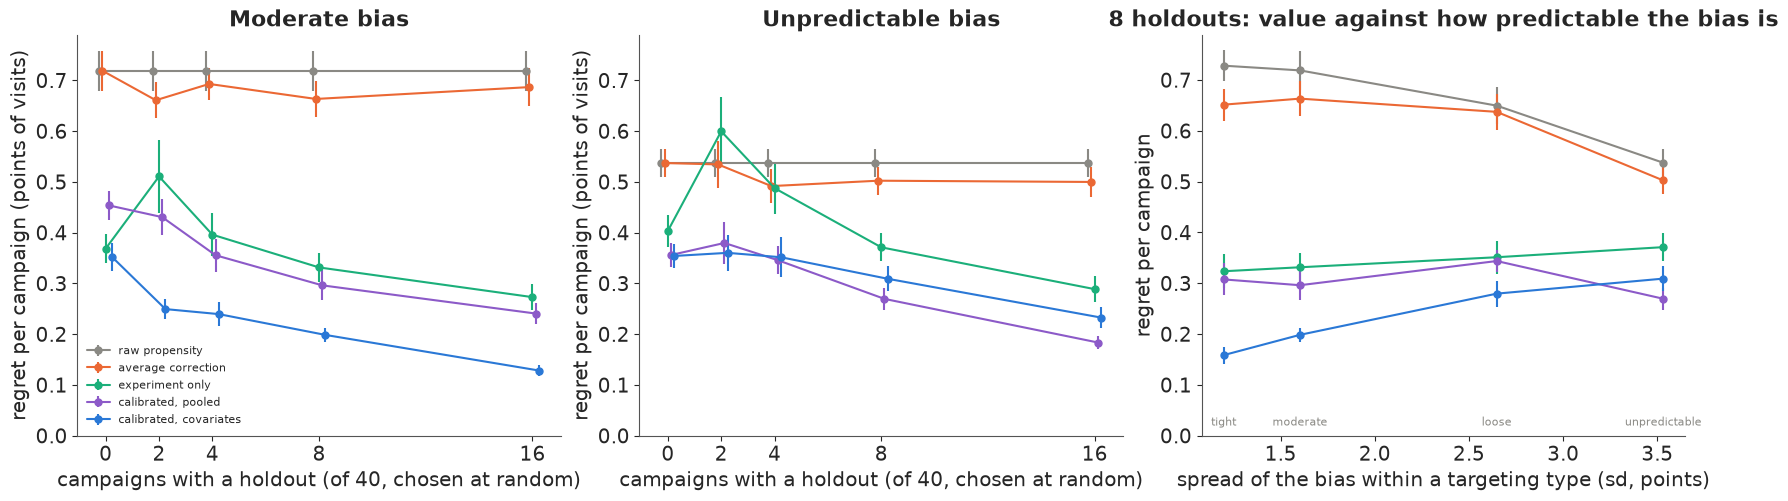

In [17]:
PCOL = {"raw propensity": MUTED, "average correction": ORANGE, "experiment only": AQUA,
        "calibrated, pooled": PURPLE, "calibrated, covariates": BLUE}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.9))
for ax, scen in zip(axes[:2], ["moderate", "unpredictable"]):
    for pol in POL:
        s_ = rr[(rr.scenario == scen) & (rr.policy == pol)].groupby("k").regret
        ax.errorbar(np.array(KS) + (POL.index(pol) - 2) * 0.12, s_.mean(), yerr=s_.sem(), fmt="o-",
                    color=PCOL[pol], ms=5, capsize=0, lw=1.5, label=pol)
    ax.set(xticks=KS, xlabel="campaigns with a holdout (of 40, chosen at random)",
           ylabel="regret per campaign (points of visits)", title=f"{scen.capitalize()} bias", ylim=(0, None))
axes[0].legend(fontsize=8)
top_ = max(a.get_ylim()[1] for a in axes[:2])
for a in axes[:2]:
    a.set_ylim(0, top_)                                             # same scale, so heights compare across panels
ax = axes[2]
xs = within.reindex(list(SCENARIOS)).to_numpy()
for pol in POL:
    s_ = rr[(rr.k == 8) & (rr.policy == pol)].groupby("scenario", sort=False).regret
    ax.errorbar(xs, s_.mean().reindex(list(SCENARIOS)), yerr=s_.sem().reindex(list(SCENARIOS)), fmt="o-",
                color=PCOL[pol], ms=5, capsize=0, lw=1.5)
for x_, s in zip(xs, SCENARIOS):
    ax.annotate(s, (x_, 0.02), fontsize=8, ha="center", color=MUTED)
ax.set(xlabel="spread of the bias within a targeting type (sd, points)", ylabel="regret per campaign",
       title="8 holdouts: value against how predictable the bias is", ylim=(0, None));

The 1,080 holdout plans take under a minute. A third of the campaigns are worth continuing, and an
oracle who kept exactly those would earn 0.69 points per campaign. **Raw propensity estimates lose
all of it**: their regret is 0.72-0.73 in the tight and moderate worlds, so cutting every campaign
would do slightly better, and 40-43% of their decisions are wrong, because a bias of 3-5 points
either way is as large as the margin between effect and cost. The **average correction** barely
helps (0.62-0.69): over a mix of types, positive and negative biases cancel, and subtracting an
average near zero changes nothing.

**When the bias follows the type, a few calibrated holdouts are worth more than the holdouts
alone.** In the moderate world (left panel) the covariate model's regret falls from 0.35 with no
holdouts to 0.25 with two, 0.20 with eight and 0.13 with sixteen; experiment-only decisions reach
0.27 with sixteen, about as good as calibration with two. Paired over the same portfolios, at
eight holdouts calibration beats experiment-only by 0.13 points per campaign (standard error
0.03). In the tight world regret is 0.16 at eight holdouts and 0.10 at sixteen, and wrong
decisions fall from raw propensity's 43% to 17% and 15%. Without any holdout, though, calibration
is worse than the prior guess in the tight world (regret 0.41 with covariates and 0.51 pooled,
against 0.33): the bias prior is symmetric and cannot know which types overstate, so the
propensity numbers are worth something only once a few experiments have measured their bias. The
pooled model does only about as well as experiment-only: with one mean bias for all types, its
$\tau$ settles at 3-4 points and it trusts no propensity estimate much.

**When the bias is unpredictable, the propensity estimates add little** (middle panel). With no
holdouts, discounting them (regret 0.35) is only a little better than deciding every campaign on
the prior guess of 3 points (0.40). The first four holdouts barely move the calibrated policies
(0.35-0.38): they teach the model that $\tau$ is large - its posterior mean rises from 2.9 with no
holdouts to 3.4 with four and 3.7 with sixteen - and an estimate that uncertain says almost
nothing about the effect. The experiments themselves then do the work: at sixteen holdouts the
pooled model reaches 0.18, the covariate model 0.23, experiment-only 0.29. Here the type
covariates are noise, and the model that estimates six extra coefficients from them pays for it;
this is the one place where the simpler calibration wins.

The right panel summarises the trade at eight holdouts. As the bias spread within a type grows
from 1.2 to 3.5 points, the covariate model's regret rises from 0.16 to 0.31 and its edge over
experiment-only shrinks from 0.17 (se 0.03) to 0.06 (se 0.04). Raw propensity looks *better* in
the unpredictable world (0.54) only because its biases average to zero there.

Two smaller findings. Experiment-only gets *worse* from zero to two holdouts (0.37 to 0.51 in the
moderate world): the average of two noisy experiments on different kinds of campaign is a worse
default for the other 38 than a sensible prior guess. And designing the holdouts across types and
reach made little difference to the covariate model: its designed and random plans are within 0.04
of each other at every $k$ in every world, sometimes ahead and sometimes behind. The cruder
policies are more sensitive to the plan: with two holdouts in the loose world, a design across
types took experiment-only from 0.67 to 0.54.

With two or more holdouts, the covariate model's 90% intervals for untested campaigns covered the
true effect 86-96% of the time in every world, against 2-21% for the raw intervals; part C's
portfolio, at 71%, was an unlucky draw of retargeting holdouts.

## E · Which campaigns get the holdouts

In practice a team tests the campaigns that matter or look interesting. Missing-data theory (Rubin
1976) says when that is harmless: if the choice depends only on things the model conditions on -
type, reach, the propensity estimate - the experiments are missing at random and the posterior
stays valid, provided the model is right. If it depends on something the model does not see, such
as a hunch, it is not.

We compare six ways of picking 8 holdouts from 40 in the moderate world, on the same 40
portfolios: **random**; **designed** across types and reach; the **top estimates**, the eight
campaigns with the largest propensity estimates, which a team might test to confirm its apparent
winners; the **suspicious** ones, where the team has a private signal of overstatement, modelled
as the true bias plus noise with sd 1 point; **suspicious within type**, the same signal used
inside a design that rotates across types; and **retargeting only**, a team that tests just the
campaigns it can test cheaply.

In [18]:
SEL_RULES = ["random", "designed", "top estimates", "suspicious", "suspicious within type", "retargeting only"]
t0 = time.time()
rs2 = np.random.default_rng(RANDOM_SEED + 5)
sel = []
for rep in range(40):
    pf = new_portfolio("moderate", rs2)
    for rule in SEL_RULES:
        t_ = np.zeros(J, bool)
        t_[test_order(pf, rule, rs2)[:8]] = True
        sel += [{**x, "rule": rule, "rep": rep} for x in evaluate(pf, t_)]
sel = pd.DataFrame(sel)
print(f"{40 * len(SEL_RULES)} portfolios with 8 holdouts in {time.time() - t0:.0f} s (moderate world)")
SP_ = ["raw propensity", "average correction", "experiment only", "calibrated, pooled", "calibrated, covariates"]
print("regret per campaign:")
print(sel.pivot_table(index="rule", columns="policy", values="regret").reindex(SEL_RULES)[SP_].round(2).to_string())
print("calibrated models on the untested: mean error (posterior mean - truth) and 90% coverage")
print(sel[sel.policy.str.startswith("calibrated")].pivot_table(index="rule", columns="policy",
      values=["error", "cover90"]).reindex(SEL_RULES).round(2).to_string())
print("bias learned by the average correction (mean propensity - experiment over the tested), by rule: "
      + ", ".join(f"{r} {v:+.1f}" for r, v in sel[sel.policy == "average correction"].groupby("rule")
                  .correction.mean().reindex(SEL_RULES).items()))
print("testing retargeting only: regret by type of campaign")
print(sel[sel.rule == "retargeting only"].groupby("policy")[[f"regret {t}" for t in TYPES]].mean()
      .reindex(SP_).round(3).to_string())

240 portfolios with 8 holdouts in 11 s (moderate world)
regret per campaign:
policy                  raw propensity  average correction  experiment only  calibrated, pooled  calibrated, covariates
rule                                                                                                                   
random                            0.66                0.64             0.34                0.38                    0.24
designed                          0.66                0.65             0.35                0.33                    0.21
top estimates                     0.66                0.56             0.39                0.41                    0.22
suspicious                        0.66                0.59             0.39                0.50                    0.24
suspicious within type            0.66                0.64             0.34                0.33                    0.21
retargeting only                  0.66                0.58             0.36        

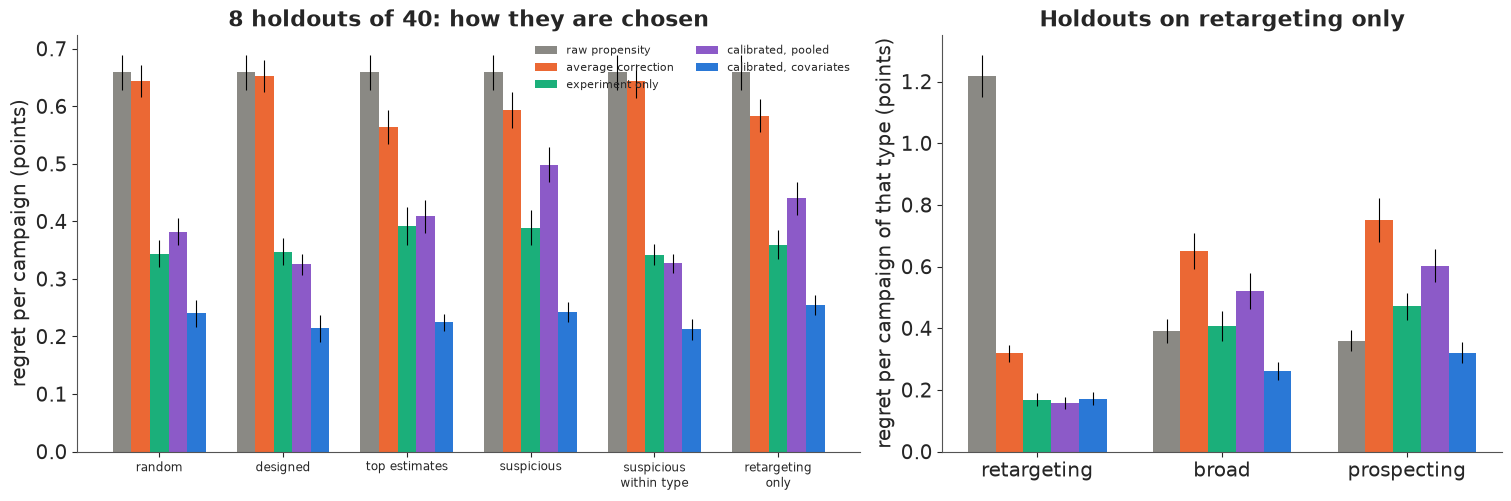

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.9), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
wdt = 0.15
for i, pol in enumerate(SP_):
    v = sel[sel.policy == pol].groupby("rule").regret
    ax.bar(np.arange(len(SEL_RULES)) + (i - 2) * wdt, v.mean().reindex(SEL_RULES), wdt,
           yerr=v.sem().reindex(SEL_RULES), color=PCOL[pol], label=pol, error_kw={"lw": 0.8})
ax.set_xticks(np.arange(len(SEL_RULES)), [r.replace(" within", "\nwithin").replace(" only", "\nonly")
                                          for r in SEL_RULES], fontsize=8.5)
ax.set(ylabel="regret per campaign (points)", title="8 holdouts of 40: how they are chosen")
ax.legend(fontsize=8, ncol=2)
ax = axes[1]
g_ = sel[sel.rule == "retargeting only"].groupby("policy")[[f"regret {t}" for t in TYPES]]
rt, rt_se = g_.mean().reindex(SP_), g_.sem().reindex(SP_)
for i, pol in enumerate(SP_):
    ax.bar(np.arange(3) + (i - 2) * wdt, rt.loc[pol].to_numpy(), wdt, yerr=rt_se.loc[pol].to_numpy(),
           color=PCOL[pol], error_kw={"lw": 0.8})
ax.set_xticks(np.arange(3), TYPES)
ax.set(ylabel="regret per campaign of that type (points)", title="Holdouts on retargeting only");

**The covariate model is robust to selection on what it sees.** Its regret stays between 0.21 and
0.25 under all six rules. Testing the top estimates is selection on an observed quantity, and the
model's estimates for the untested are off by half a point on average (-0.54) with 96% coverage;
the residual comes from what the Gaussian model gets wrong (gamma-distributed effects, a bias that
need not be linear in reach). The same rule hurts the policies that do not condition on the
choice: experiment-only rises to 0.39, because the average experiment over the eight most
impressive campaigns - mostly retargeting - is a poor default for the other 32, and the pooled
model to 0.41.

**Selection on a hidden hunch biases the calibration.** When the tested campaigns are the
suspicious ones, the covariate model learns too large a bias and over-corrects: its estimates for
the untested are about one point too low on average (-1.12 across all campaigns, -1.06 within
types), while its coverage stays near that of random choice (94% and 84%, against 85%): the
intervals are wide enough to hide a systematic error. Here that changed few decisions (regret 0.24
and 0.21), because one point is small next to the spread of costs, but it is systematic, it would
grow with a stronger hunch, and nothing in the tested data reveals it. The pooled model suffers
more: 2.4 points too low, 68% coverage, regret 0.50.

**A correction carried across types does harm** (right panel). With holdouts on retargeting only,
the average correction learns a bias of +4.7 points and subtracts it from everyone; the pooled
model, which also has only retargeting to learn from, pulls the same way. For broad and
prospecting campaigns, whose true bias is about -3, that turns an understatement of 3 points into
one of 8: their regret is 0.65 and 0.75 with the average correction and 0.52 and 0.60 with the
pooled model, against 0.39 and 0.36 for the raw estimates - worse than no correction for every
campaign unlike the tested ones. The covariate model has no holdout for those types and says so
through a wide bias prior; it falls back on discounting their propensity estimates and keeps their
regret at 0.26 and 0.32.

## F · What the brand team should do

The question was whether a few holdouts, combined with propensity estimates on every campaign,
improve decisions. In these simulations they do, by a lot, when the bias is predictable from what
the team records about each campaign: eight calibrated holdouts out of forty cut the regret of
trusting the propensity numbers by about three quarters and beat deciding from the eight
experiments alone by 0.13-0.17 points per campaign, a fifth to a quarter of everything the
portfolio could earn. When the bias was not predictable, the propensity estimates were close to
worthless for decisions, calibration mainly taught the model to ignore them, and the value came
from the experiments.

**How many holdouts.** With the type in the model, two holdouts already took the moderate world's
regret from 0.35 to 0.25, and in the tight world returns diminished after eight. These regrets
leave out what a holdout costs - the survey and the audience held back - which a team must weigh
against the 0.05-0.1 points per campaign that eight more holdouts bought in the predictable
worlds. A team that does not yet know how predictable its bias is should start with enough
holdouts to estimate $\tau$ - about two per targeting type - and let its posterior decide: a
$\tau$ small next to the biases says the propensity numbers can be calibrated; a $\tau$ as large
as the biases says to stop trusting them and run more experiments.

**Which campaigns.** Cover every kind of campaign whose numbers will be corrected: a correction
learned on retargeting and applied to prospecting was worse than none. Within a type, choose at
random or by a rule fixed in advance from recorded features - reach, budget, the propensity
estimate itself - never by suspicion, whose bias the tested campaigns cannot reveal. Keep some
holdouts on the campaigns that matter most, since shrinkage fails exactly where a campaign departs
from its type.

**What to record, model and report.** The covariates make calibration work, so record the delivery
ingredients E102 identified - retargeting pools, suppression and exclusion lists, prospecting
share, reach - and let both the bias and the true effect depend on them. Report each campaign's
calibrated interval, never the propensity analysis's own: the raw intervals covered the truth
2-21% of the time, the calibrated ones 86-96%.

**Refresh, and know when to stop.** The bias belongs to a delivery process, not to a brand: when
targeting rules, platforms or suppression lists change, give the new kind of campaign its own
covariate and its own holdouts. And if $\tau$ stays near the size of the biases after a dozen
holdouts, or the important decisions sit near their break-even point, the propensity estimates are
not earning their place: run ghost-ad holdouts on the campaigns that matter and treat the
propensity numbers for the rest as the weak evidence the model says they are.

In [20]:
print(f"total run time {time.time() - T_START:.0f} s")

total run time 111 s


## Summary

- **A propensity estimate is its true effect plus a bias that a placebo run measures exactly**
  (difference about 4e-16). Across 720 simulated campaigns on E102's real users the bias followed
  the targeting type: +4 to +5.5 points for retargeting, -2 to -3.5 for broad campaigns with
  suppression lists and for prospecting. The limit: simulated delivery on one audience with one
  hidden trait.
- **The bias model needs its effects integrated out.** With a latent effect per campaign NUTS hit
  a funnel in $\tau$ (60-115 divergences); the marginal model had none, and an exact grid
  posterior matched it to 0.1 point.
- **Calibrated intervals cover; raw ones do not.** Over 120 portfolios, calibrated 90% intervals
  covered the untested effects 86-96% of the time with two or more holdouts, raw ones 2-21%. A
  single portfolio can still miss a whole type (71%) when its few holdouts are unrepresentative.
- **When the bias is predictable, a few holdouts change the decisions.** Perfect information
  earned 0.69 points per campaign; raw propensity estimates lost all of it (regret 0.72-0.73,
  40-43% wrong). With 8 holdouts of 40, calibrated regret was 0.16-0.20 against 0.32-0.33 for
  experiment-only decisions (paired gain 0.13-0.17, se 0.03).
- **When it is not, calibration mostly teaches the model to ignore the propensity estimates.** In
  the unpredictable world the first four holdouts barely helped (regret about 0.35), $\tau$ rose
  from 2.9 to 3.7 points by sixteen, the edge over experiment-only fell to 0.06 (se 0.04), and the
  pooled model beat the covariate model.
- **Who gets the holdouts matters.** The covariate model kept its regret at 0.21-0.25 under six
  selection rules, but a hidden hunch biased its estimates by about a point. Holdouts on
  retargeting only made a pooled correction worse than none for broad and prospecting campaigns
  (regret 0.52-0.75 against 0.36-0.39).

## Try it yourself

1. **Value of the next holdout.** For one portfolio, compute for each untested campaign the
   expected value of sample information of a ghost-ad holdout: simulate its experiment from the
   posterior, update with the grid posterior (which also updates the type's bias for everyone
   else), and average the improvement in the decisions. Does the best next test go to the campaign
   nearest its break-even point, or to the least-tested type?
2. **Heavy-tailed bias.** Replace the normal bias in the model by a Student-t with unknown degrees
   of freedom and fit it in PyMC on a portfolio from the loose world. Does it treat the 4%-reach
   retargeting campaign as an outlier, and does that improve coverage of the other retargeting
   campaigns?
3. **A drifting delivery process.** Let half the portfolio's prospecting campaigns switch to a new
   platform where $\gamma_j$ is centred on 0 instead of -0.7, with no covariate to mark them. How
   quickly do the calibrated intervals lose coverage, and how many holdouts on the new platform
   restore it once it gets its own covariate?